# 2. Modelos y optimización de hiperparámetros

## 2.1 Diseño experimental

La tarea es de **regresión**, por lo que la etapa de balanceo de clases no aplica (Sección 2 de la guía):

| Etapa | Alternativas | n |
|---|---|---|
| 1. Modelos base | KNN, Ridge, Lasso, Decision Tree, Random Forest, XGBoost, SVR (RBF) | 7 |
| 2. Balanceo | No aplica en regresión | — |
| 3. Optimización | Grid Search, Random Search, Bayesiana (Optuna-TPE), Genética (DEAP) | 4 |
| **Total escenario A (principal)** | 7 × 4 | **28 combinaciones** |
| Escenario B (sensibilidad, con `BrentDifferential`) | 7 × Bayesiana | 7 |

**Validación anidada (Sección 3.2).**

- *Hold-out* por activo: 20 % de los activos (139) se reserva y no se usa hasta la evaluación final.
- **Bucle externo:** `GroupKFold(10)` por activo sobre los 556 activos de desarrollo (~56 activos y ~300
  filas por pliegue). Diez pliegues dan diez bloques para el test de Friedman y suficiente tamaño de prueba
  por pliegue; con n ≈ 3.000 el costo de 10 pliegues es asumible.
- **Bucle interno:** `GroupKFold(3)` por activo dentro de cada entrenamiento externo (~500 activos). Tres
  pliegues bastan para ordenar configuraciones y mantienen el costo total en 7 × 4 × 11 búsquedas × 30
  evaluaciones × 3 ajustes ≈ 28.000 entrenamientos.
- Las métricas reportadas salen del **bucle externo**; el RMSE del bucle interno solo se usa para elegir
  hiperparámetros.
- Después de la CV anidada se repite la búsqueda sobre todo el desarrollo (búsqueda *final*) y ese modelo
  se evalúa en el hold-out.

**Presupuesto igual para todos los métodos:** 30 evaluaciones por búsqueda (cada evaluación = CV interna
de 3 pliegues del Pipeline completo). Grid Search usa la rejilla más grande que cabe en 30 puntos.

**Sin fuga de información:** en los cuatro métodos cada evaluación ajusta el `Pipeline`
(imputación + log + escalado + One-Hot + modelo) dentro del pliegue. En Optuna y DEAP el pipeline se
construye manualmente en la función objetivo (`src/optimizers.py`).

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config as C
from src.models import MODELS, MODEL_ORDER
from src.optimizers import build_grid, GA_CONFIG, METHODS
from src.nested_cv import collect, master_table, anytime_table
from src.viz import set_style, MODEL_COLORS, METHOD_COLORS, SERIES, INK2, MUTED

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 120)

res = collect()
resA = [r for r in res if r["scenario"] == "A_estructural"]
mt = pd.read_csv(C.RESULTS_DIR / "master_table.csv")
mtA = mt[mt["scenario"] == "A_estructural"].copy()
print(f"Tareas registradas: {len(res)} | combinaciones escenario A: {len(mtA)} | escenario B: {(mt.scenario == 'B_con_BD').sum()}")
print(f"Evaluaciones totales (escenario A): {int(mtA['total_evals'].sum()):,} configuraciones x 3 pliegues internos")

Tareas registradas: 385 | combinaciones escenario A: 28 | escenario B: 7
Evaluaciones totales (escenario A): 9,020 configuraciones x 3 pliegues internos


## 2.2 Espacios de búsqueda

Los espacios se definen una sola vez (`src/models.py`) y los cuatro optimizadores los traducen a su
formato. Los hiperparámetros de escala (C, γ, ε, λ, *learning rate*, `min_child_weight`) se exploran en
escala logarítmica.

In [2]:
rows = []
for name in MODEL_ORDER:
    spec = MODELS[name]
    grid = build_grid(spec.space, C.BUDGET)
    for p in spec.space:
        dom = str(p.choices) if p.kind == "cat" else f"[{p.low:g}, {p.high:g}]" + (" (log)" if p.log else "")
        rows.append({"modelo": name, "hiperparámetro": p.name, "tipo": p.kind, "dominio": dom,
                     "niveles en Grid": len(grid[p.name])})
spaces = pd.DataFrame(rows)
spaces

,modelo,hiperparámetro,tipo,dominio,niveles en Grid
0,KNN,n_neighbors,int,"[2, 60] (log)",7
1,KNN,weights,cat,"['uniform', 'distance']",2
2,KNN,p,cat,"[1, 2]",2
3,Ridge,alpha,float,"[0.001, 1000] (log)",30
4,Lasso,alpha,float,"[0.0001, 10] (log)",30
5,DecisionTree,max_depth,int,"[2, 25]",3
6,DecisionTree,min_samples_leaf,int,"[1, 50] (log)",3
7,DecisionTree,min_samples_split,int,"[2, 40] (log)",3
8,RandomForest,max_features,float,"[0.1, 1]",3
9,RandomForest,min_samples_leaf,int,"[1, 20] (log)",2


In [3]:
pd.DataFrame([{"modelo": n, "puntos de la rejilla": int(np.prod([len(v) for v in build_grid(MODELS[n].space, C.BUDGET).values()])),
               "dimensión": len(MODELS[n].space), "justificación": MODELS[n].justification} for n in MODEL_ORDER])

,modelo,puntos de la rejilla,dimensión,justificación
0,KNN,28,3,"k en escala log (2–60): con ~2.4k filas de entrenamiento, k>60 suaviza en exceso; distance vs uniform y métrica Manh..."
1,Ridge,30,1,λ en escala log de 1e-3 a 1e3: cubre desde OLS casi sin penalización hasta coeficientes muy contraídos.
2,Lasso,30,1,λ log 1e-4–10: con target en USD/Bbl (σ≈5.5) λ>10 anula todos los coeficientes.
3,DecisionTree,27,3,Profundidad 2–25 y hojas mínimas 1–50 (log): controlan el sobreajuste.
4,RandomForest,24,4,max_features (decorrelación de árboles) es el más influyente; n_estimators acotado a 300 porque el error se estabili...
5,XGBoost,24,7,learning_rate y n_estimators interactúan (lr bajo requiere más árboles); subsample/colsample introducen aleatoriedad...
6,SVR,27,3,"Kernel RBF (el SVR lineal fue el modelo base del entregable 1). C, γ y ε en escala log; ε hasta 2 USD/Bbl (≈ RMSE de..."


**Interpretación.** Con 30 evaluaciones, Grid Search solo es exhaustivo en espacios de baja dimensión: Ridge
y Lasso (1 hiperparámetro) reciben 30 niveles de λ, pero XGBoost (7 hiperparámetros) solo puede variar 4 de
ellos con 2–3 niveles (24 puntos) y deja `colsample_bytree`, `min_child_weight` y `reg_lambda` fijos en el
punto medio. SVR recibe 3 niveles de C, γ y ε (27 puntos) en rangos de 4 a 5 órdenes de magnitud. Esta es
la limitación estructural de Grid frente a métodos que muestrean el espacio de forma continua.

## 2.3 Tabla maestra de resultados (escenario A)

Una fila por combinación. Métricas del **bucle externo** como media ± desviación estándar entre los 10
pliegues; tiempos en segundos de reloj (*wall-clock*) incluyendo las 11 búsquedas de la combinación.

In [4]:
def pm(m, s, d=3):
    return f"{m:.{d}f} ± {s:.{d}f}"

tbl = mtA.assign(
    RMSE=[pm(a, b) for a, b in zip(mtA.outer_rmse_mean, mtA.outer_rmse_std)],
    MAE=[pm(a, b) for a, b in zip(mtA.outer_mae_mean, mtA.outer_mae_std)],
    R2=[pm(a, b) for a, b in zip(mtA.outer_r2_mean, mtA.outer_r2_std)],
    MAPE=[pm(a, b, 1) for a, b in zip(mtA.outer_mape_mean, mtA.outer_mape_std)],
)[["model", "method", "RMSE", "MAE", "R2", "MAPE", "inner_rmse_mean", "evals_per_search",
   "total_evals", "search_time_total_s", "time_per_eval_s"]]
tbl.columns = ["Modelo", "Optimizador", "RMSE externo", "MAE externo", "R² externo", "MAPE % externo",
               "RMSE interno", "Evals/búsqueda", "Evals totales", "Tiempo total (s)", "s/evaluación"]
tbl.reset_index(drop=True)

,Modelo,Optimizador,RMSE externo,MAE externo,R² externo,MAPE % externo,RMSE interno,Evals/búsqueda,Evals totales,Tiempo total (s),s/evaluación
0,RandomForest,Random,2.008 ± 0.549,1.095 ± 0.228,0.856 ± 0.066,7.7 ± 1.4,2.198,30.000,330,895.202,2.778
1,RandomForest,Genetica,2.038 ± 0.566,1.087 ± 0.249,0.853 ± 0.067,7.6 ± 1.6,2.192,30.000,330,545.553,1.627
2,RandomForest,Grid,2.056 ± 0.606,1.094 ± 0.254,0.849 ± 0.075,7.6 ± 1.6,2.208,24.000,264,446.815,1.673
3,XGBoost,Grid,2.057 ± 0.600,1.176 ± 0.238,0.848 ± 0.078,8.5 ± 1.5,2.264,24.000,264,202.727,0.762
4,XGBoost,Bayesiana,2.058 ± 0.613,1.202 ± 0.246,0.848 ± 0.082,8.8 ± 1.6,2.192,30.000,330,327.368,0.969
5,XGBoost,Random,2.070 ± 0.619,1.187 ± 0.261,0.846 ± 0.079,8.6 ± 1.6,2.226,30.000,330,247.639,0.743
6,RandomForest,Bayesiana,2.076 ± 0.564,1.110 ± 0.237,0.845 ± 0.077,7.8 ± 1.6,2.189,30.000,330,775.489,2.339
7,XGBoost,Genetica,2.078 ± 0.609,1.247 ± 0.233,0.847 ± 0.075,9.1 ± 1.3,2.198,30.000,330,197.428,0.596
8,SVR,Bayesiana,2.187 ± 0.529,1.242 ± 0.214,0.835 ± 0.056,8.8 ± 1.7,2.411,30.000,330,580.035,1.706
9,SVR,Random,2.349 ± 0.610,1.323 ± 0.269,0.811 ± 0.065,9.2 ± 2.0,2.559,30.000,330,421.200,1.249


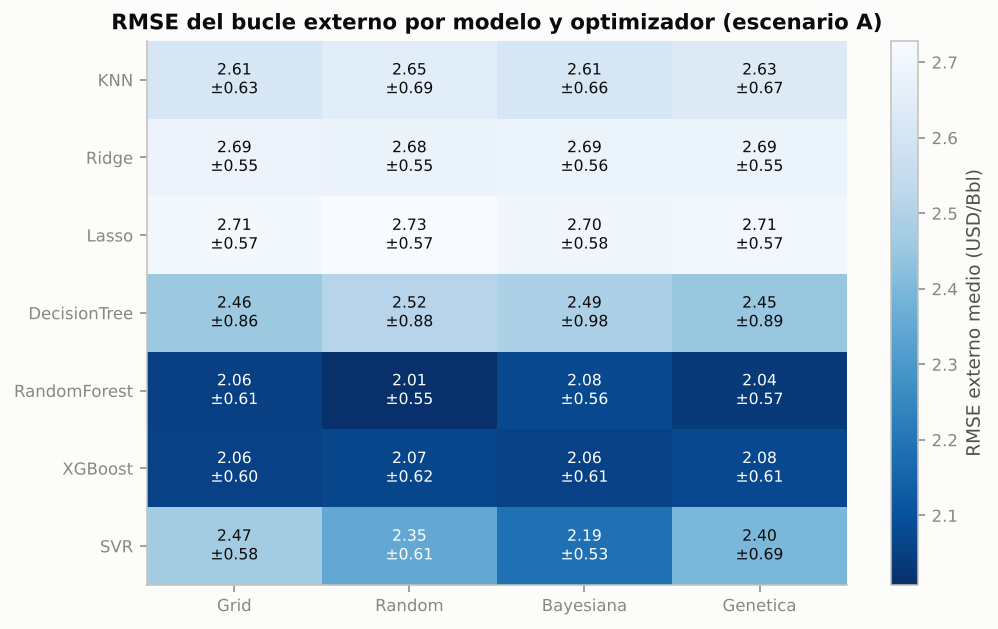

In [5]:
piv = mtA.pivot(index="model", columns="method", values="outer_rmse_mean").loc[MODEL_ORDER, METHODS]
pivs = mtA.pivot(index="model", columns="method", values="outer_rmse_std").loc[MODEL_ORDER, METHODS]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(piv.values, cmap="Blues_r", aspect="auto")
ax.set_xticks(range(4), METHODS)
ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER)
ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:.2f}\n±{pivs.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v < np.nanpercentile(piv.values, 35) else "#0b0b0b")
fig.colorbar(im, ax=ax, label="RMSE externo medio (USD/Bbl)")
ax.set_title("RMSE del bucle externo por modelo y optimizador (escenario A)")
plt.tight_layout()

**Interpretación.**

- **Familias de modelos.** Los ensambles de árboles dominan: Random Forest (RMSE externo 2.01–2.08) y
  XGBoost (2.06–2.08) quedan prácticamente empatados, seguidos de SVR-RBF (2.19 con Bayesiana). Los modelos
  lineales (Ridge, Lasso ≈ 2.69–2.73, R² ≈ 0.74–0.75) y KNN (≈ 2.61–2.65) son los más débiles: el costo
  depende de interacciones entre geografía, tipo de activo y año que un modelo aditivo no captura.
- **Optimizadores.** Dentro de cada familia las diferencias entre optimizadores son pequeñas frente a la
  desviación entre pliegues (±0.55–0.98). La excepción es **SVR**: la Bayesiana (2.19) supera a Random
  (2.35), Genética (2.40) y Grid (2.47). SVR tiene tres hiperparámetros continuos en escala log que
  interactúan (C × γ); ahí el modelo sustituto aprovecha la estructura y Grid, con 3 niveles por eje,
  no alcanza la región buena.
- **Variabilidad entre pliegues.** La desviación estándar (≈ 0.55–0.6 en los mejores) es diez veces mayor
  que la diferencia entre los cuatro primeros puestos (≈ 0.05). Esto anticipa que muchas diferencias no
  serán significativas y motiva las pruebas formales del capítulo 5.
- **Costo.** Random Forest es el más caro (1.6–2.8 s por evaluación; hasta 15 min por combinación) y
  XGBoost logra el mismo error con 2–4 veces menos tiempo. Los modelos lineales y el árbol cuestan
  ~0.1 s por evaluación.
- **Frente al entregable 1.** El SVR lineal del entregable 1 reportaba R² = 0.857 **con** `BrentDifferential`;
  sin esa variable los mejores modelos del escenario A alcanzan R² externo ≈ 0.85, es decir, recuperan el
  desempeño sin usar un componente del target.

## 2.4 ¿Por qué validación anidada? Sesgo optimista del bucle interno

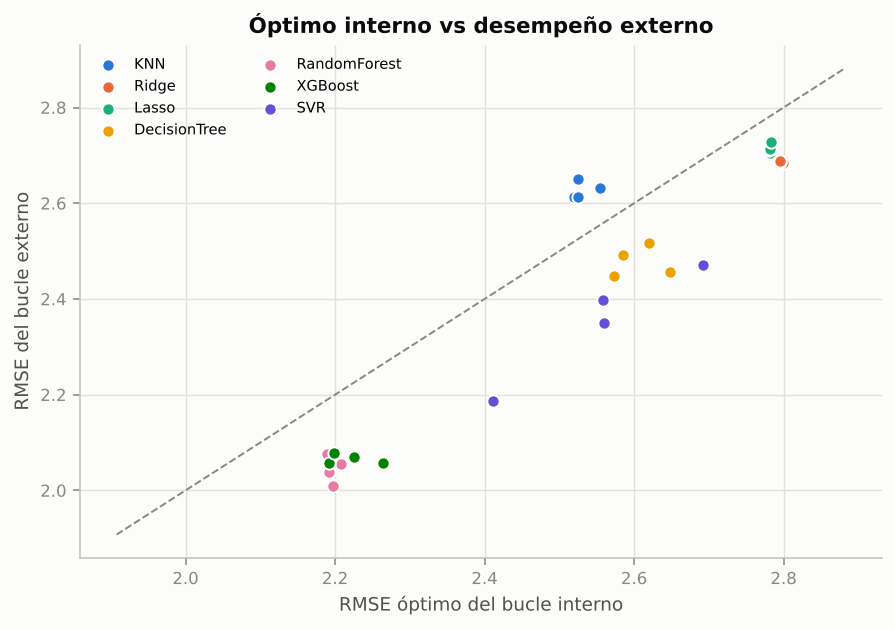

,RMSE externo − interno (media)
model,
KNN,0.096
Ridge,-0.110
Lasso,-0.067
DecisionTree,-0.129
RandomForest,-0.152
XGBoost,-0.154
SVR,-0.204


In [6]:
opt = mtA.assign(gap=mtA.outer_rmse_mean - mtA.inner_rmse_mean)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for m in MODEL_ORDER:
    s = opt[opt.model == m]
    ax.scatter(s.inner_rmse_mean, s.outer_rmse_mean, s=40, color=MODEL_COLORS[m], label=m, edgecolor="white", lw=1)
lims = [opt[["inner_rmse_mean", "outer_rmse_mean"]].min().min() * 0.95, opt[["inner_rmse_mean", "outer_rmse_mean"]].max().max() * 1.03]
ax.plot(lims, lims, color=MUTED, ls="--", lw=1)
ax.set(xlabel="RMSE óptimo del bucle interno", ylabel="RMSE del bucle externo", title="Óptimo interno vs desempeño externo")
ax.legend(ncol=2, fontsize=7.5)
plt.tight_layout()
opt.groupby("model")["gap"].mean().rename("RMSE externo − interno (media)").to_frame().loc[MODEL_ORDER]

**Interpretación.** Contra lo que suele esperarse, el RMSE externo es **menor** que el óptimo interno en
seis de los siete modelos (diferencias de −0.07 a −0.20); solo KNN muestra el sesgo optimista clásico
(+0.10). La razón es el tamaño de entrenamiento: en el bucle interno cada modelo se entrena con 2/3 del
entrenamiento externo (~1.850 filas) y se evalúa en 1/3, mientras que en el externo se reentrena con todo
(~2.780 filas). Con una curva de aprendizaje que todavía mejora, ese efecto supera al sesgo de selección.

El mensaje metodológico se mantiene: el valor interno **no** es un estimador confiable del desempeño (aquí
es pesimista; en KNN, optimista). Por eso las métricas que se reportan y comparan salen del bucle externo.

## 2.5 Convergencia: curvas de desempeño *anytime*

Para cada búsqueda se registra el mejor RMSE interno encontrado hasta la evaluación *t*. Las curvas
muestran la mediana entre los 10 pliegues externos. Para Grid Search el orden de evaluación es el de la
rejilla (no adaptativo), que es justamente su limitación.

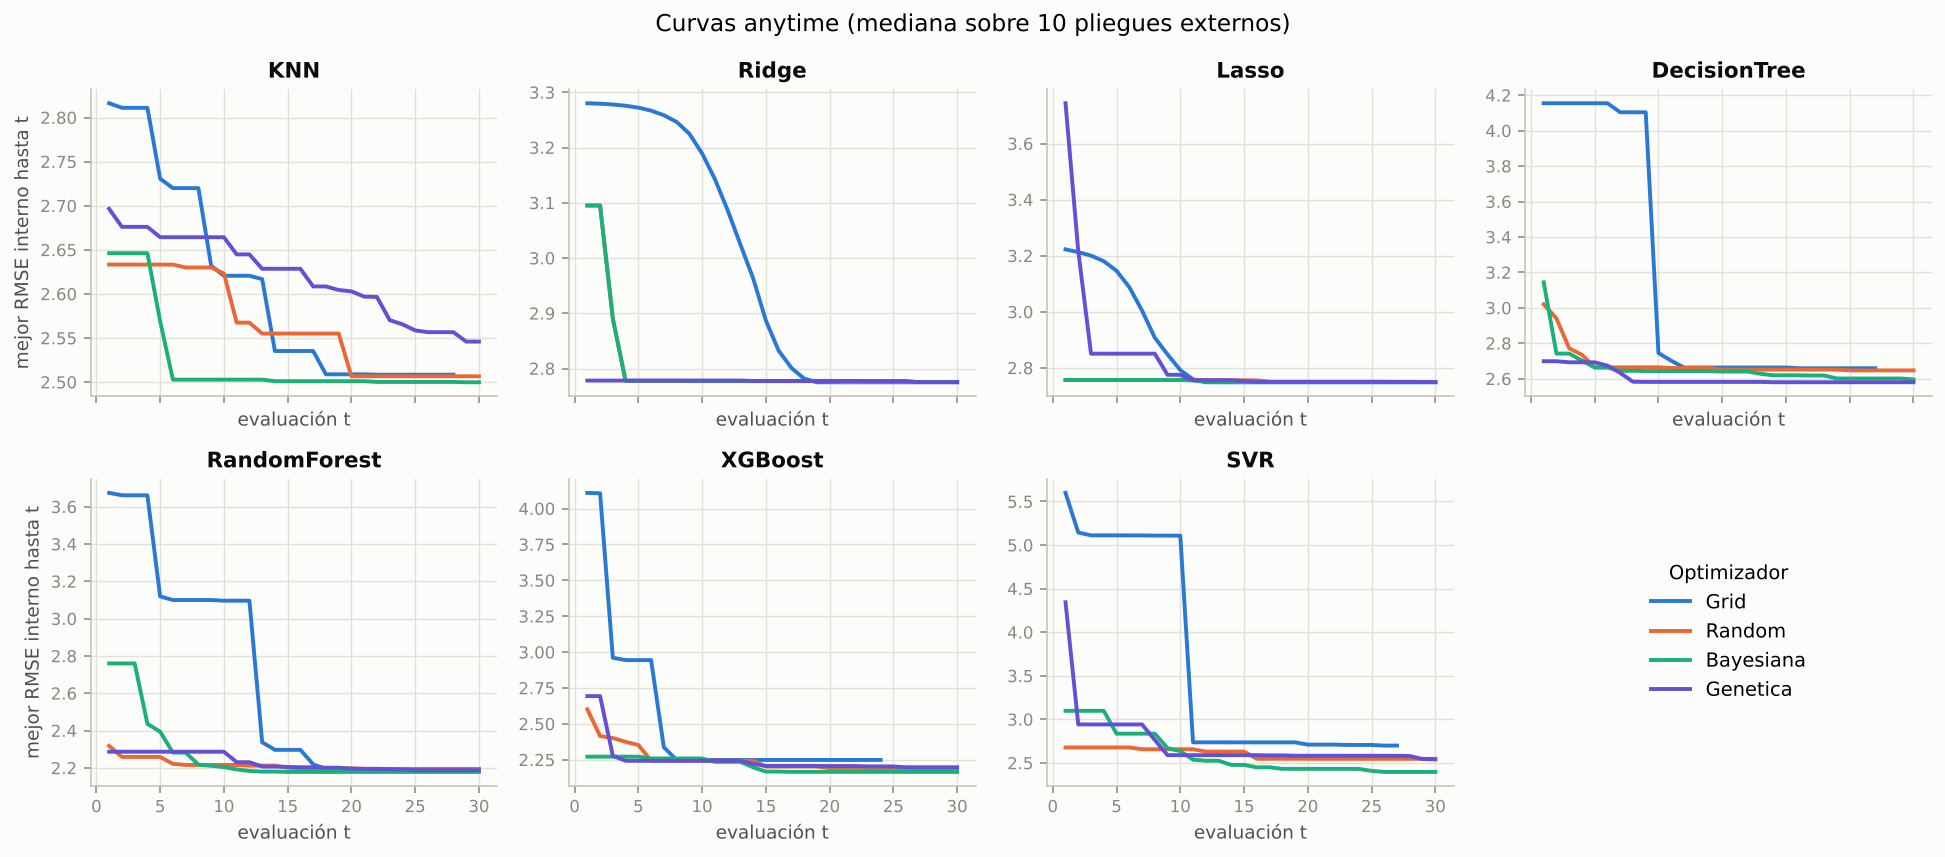

In [7]:
at = anytime_table(resA)
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2), sharex=True)
for ax, m in zip(axes.flat, MODEL_ORDER):
    for me in METHODS:
        s = at[(at.model == m) & (at.method == me)]
        cur = s.groupby("eval")["best_so_far"].median()
        ax.plot(cur.index, cur.values, color=METHOD_COLORS[me], lw=2, label=me)
    ax.set_title(m)
    ax.set_xlabel("evaluación t")
axes.flat[0].set_ylabel("mejor RMSE interno hasta t")
axes.flat[4].set_ylabel("mejor RMSE interno hasta t")
axes.flat[-1].axis("off")
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h, l, loc="center", fontsize=10, title="Optimizador")
fig.suptitle("Curvas anytime (mediana sobre 10 pliegues externos)", fontsize=12)
plt.tight_layout()

### Evidencia cuantitativa de eficiencia

Para cada búsqueda (modelo × pliegue) se normaliza el RMSE para hacer comparables los modelos:
*regret* relativo = (mejor-hasta-t − mejor global de ese modelo y pliegue) / mejor global. Se reportan:

- **Regret en t = 10, 20, 30** evaluaciones.
- **Área bajo la curva anytime** (regret medio sobre t = 1..30): menor = alcanza buenas soluciones antes.
- **Evaluaciones para quedar a ≤ 1 % del mejor** global.
- **Calidad por unidad de presupuesto:** prueba de Wilcoxon pareada (70 búsquedas = 7 modelos × 10
  pliegues) del área anytime de cada método contra Random Search, con corrección de Holm.

In [8]:
from src.stats_tests import holm, cliffs_delta

at_ = at.copy()
best_global = at_.groupby(["model", "fold"])["rmse"].min().rename("g")
at_ = at_.join(best_global, on=["model", "fold"])
at_["regret"] = (at_["best_so_far"] - at_["g"]) / at_["g"] * 100
B = C.BUDGET

def pad(s):
    # Grid puede tener < 30 puntos: se extiende con su último valor (no puede mejorar más)
    s = s.set_index("eval")["regret"].reindex(range(1, B + 1)).ffill()
    return s

rows = []
for (m, f, me), s in at_.groupby(["model", "fold", "method"]):
    r = pad(s)
    reach = r[r <= 1.0]
    rows.append({"model": m, "fold": f, "method": me, "regret_t10": r.loc[10], "regret_t20": r.loc[20],
                 "regret_t30": r.loc[B], "auc_regret": r.mean(),
                 "evals_to_1pct": int(reach.index.min()) if len(reach) else np.nan})
eff = pd.DataFrame(rows)
summary = eff.groupby("method").agg(
    regret_t10=("regret_t10", "median"), regret_t20=("regret_t20", "median"), regret_t30=("regret_t30", "median"),
    auc_regret=("auc_regret", "median"), evals_to_1pct=("evals_to_1pct", "median"),
    pct_alcanza_1pct=("evals_to_1pct", lambda x: 100 * x.notna().mean())).loc[METHODS]
summary.columns = ["Regret % t=10", "Regret % t=20", "Regret % t=30", "AUC regret %", "Evals a ≤1 % (mediana)", "% búsquedas que llegan a ≤1 %"]
summary

,Regret % t=10,Regret % t=20,Regret % t=30,AUC regret %,Evals a ≤1 % (mediana),% búsquedas que llegan a ≤1 %
method,,,,,,
Grid,6.302,0.938,0.656,14.425,17.000,51.429
Random,2.050,0.551,0.517,1.914,6.000,61.429
Bayesiana,0.912,0.062,0.000,1.853,9.000,92.857
Genetica,2.894,0.723,0.024,2.427,11.000,71.429


In [9]:
piv_auc = eff.pivot_table(index=["model", "fold"], columns="method", values="auc_regret")
piv_t30 = eff.pivot_table(index=["model", "fold"], columns="method", values="regret_t30")
rows = []
for crit, pv in [("AUC regret (rapidez)", piv_auc), ("regret final t=30 (calidad)", piv_t30)]:
    for me in ["Grid", "Bayesiana", "Genetica"]:
        w = stats.wilcoxon(pv[me], pv["Random"], zero_method="zsplit")
        d, mag = cliffs_delta(pv[me], pv["Random"])
        rows.append({"criterio": crit, "comparación": f"{me} vs Random", "mediana método": pv[me].median(),
                     "mediana Random": pv["Random"].median(), "W": w.statistic, "p crudo": w.pvalue,
                     "δ de Cliff": d, "magnitud": mag})
wil = pd.DataFrame(rows)
wil["p Holm"] = holm(wil["p crudo"])
wil

,criterio,comparación,mediana método,mediana Random,W,p crudo,δ de Cliff,magnitud,p Holm
0,AUC regret (rapidez),Grid vs Random,14.425,1.914,12.000,0.000,0.660,grande,0.000
1,AUC regret (rapidez),Bayesiana vs Random,1.853,1.914,822.000,0.014,-0.068,despreciable,0.028
2,AUC regret (rapidez),Genetica vs Random,2.427,1.914,857.000,0.024,0.102,despreciable,0.028
3,regret final t=30 (calidad),Grid vs Random,0.656,0.517,588.000,0.000,0.047,despreciable,0.001
4,regret final t=30 (calidad),Bayesiana vs Random,0.000,0.517,223.000,0.000,-0.645,grande,0.000
5,regret final t=30 (calidad),Genetica vs Random,0.024,0.517,757.500,0.005,-0.298,pequeño,0.014


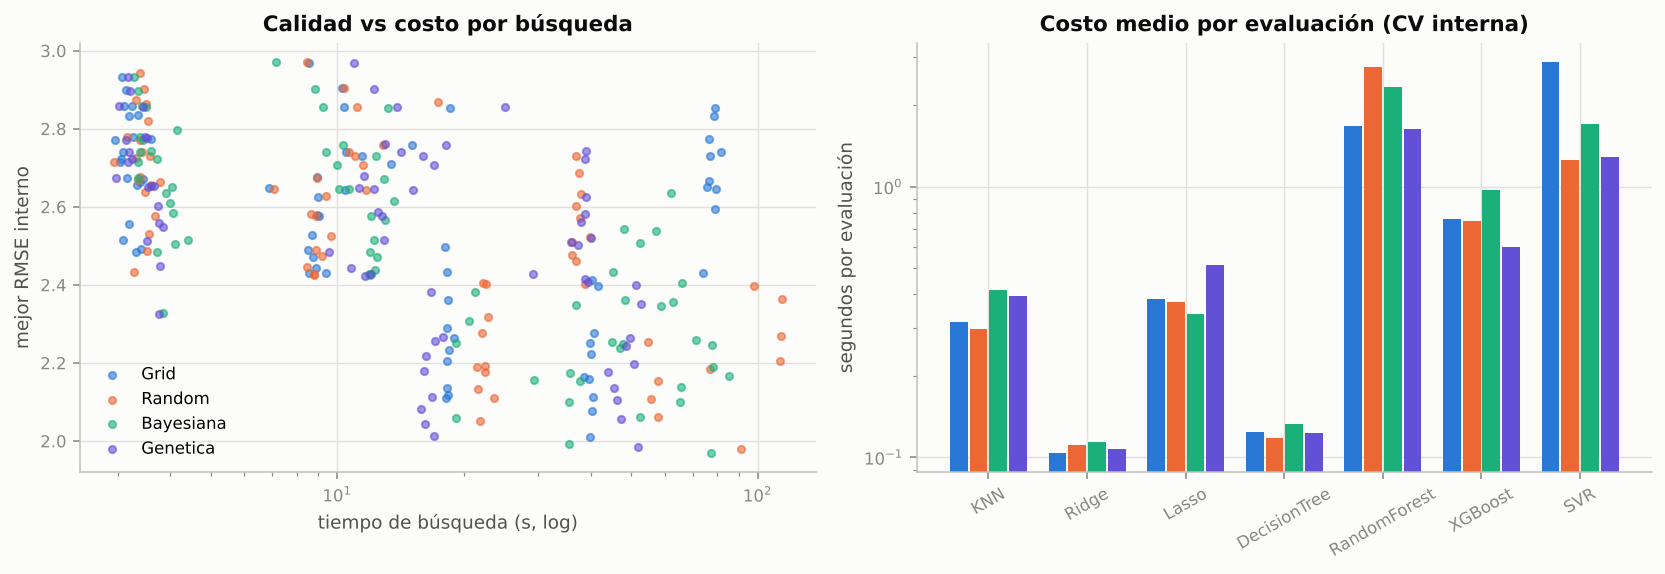

In [10]:
# Calidad por unidad de tiempo: mejor RMSE alcanzado vs segundos de búsqueda (todas las búsquedas externas)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
tt = pd.DataFrame([{"model": r["model"], "method": r["method"], "time": r["search_time"], "rmse": r["best_inner_rmse"]}
                   for r in resA if r["fold"] != "final"])
for me in METHODS:
    s = tt[tt.method == me]
    axes[0].scatter(s.time, s.rmse, s=14, alpha=0.6, color=METHOD_COLORS[me], label=me)
axes[0].set(xscale="log", xlabel="tiempo de búsqueda (s, log)", ylabel="mejor RMSE interno", title="Calidad vs costo por búsqueda")
axes[0].legend()
tm = mtA.pivot(index="model", columns="method", values="time_per_eval_s").loc[MODEL_ORDER, METHODS]
x = np.arange(len(MODEL_ORDER))
for k, me in enumerate(METHODS):
    axes[1].bar(x + (k - 1.5) * 0.2, tm[me], width=0.18, color=METHOD_COLORS[me], label=me)
axes[1].set_xticks(x, MODEL_ORDER, rotation=30)
axes[1].set(ylabel="segundos por evaluación", yscale="log", title="Costo medio por evaluación (CV interna)")
plt.tight_layout()

**Interpretación (eficiencia por unidad de presupuesto).**

- **Calidad final con el mismo presupuesto (t = 30).** La optimización Bayesiana termina en el mejor punto
  encontrado por cualquier método en la mediana de las búsquedas (regret 0.00 %) y llega a ≤ 1 % del óptimo
  en el **93 %** de las 70 búsquedas, frente al 61 % de Random, 71 % del GA y 51 % de Grid. Frente a Random
  la diferencia es significativa con efecto **grande** (Wilcoxon, p Holm < 0.001, δ de Cliff = −0.65). El GA
  también supera a Random en calidad final (p Holm = 0.014), con efecto pequeño (δ = −0.30).
- **Rapidez (área bajo la curva anytime).** Random es muy difícil de superar en las primeras evaluaciones:
  Bayesiana y Random tienen un área casi igual (1.85 vs 1.91 %; efecto despreciable aunque p < 0.05),
  porque los primeros 8 ensayos de TPE *son* aleatorios. El GA es algo más lento al inicio (δ = +0.10).
- **Grid** es el peor en rapidez con efecto grande (área 14.4 % vs 1.9 %; δ = +0.66): recorre la rejilla en
  orden fijo y puede gastar la mitad del presupuesto en una región mala (curvas de RF, SVR y KNN).
- **Calidad por segundo.** El costo por evaluación es casi idéntico entre métodos para un mismo modelo
  (lo domina el ajuste del Pipeline, no la lógica del optimizador), así que la ventaja de la Bayesiana en
  calidad final es también una ventaja por unidad de tiempo. El *overhead* del TPE (milisegundos) es
  despreciable frente a evaluaciones de 0.1–3 s.

**Conclusión.** La evidencia cuantitativa respalda que la optimización Bayesiana es más eficiente que
Grid/Random en calidad alcanzada por presupuesto. Sin embargo, como se verá en el capítulo 5, esas mejoras en
el RMSE **interno** (décimas de punto porcentual) no se traducen en diferencias significativas del RMSE
**externo** entre optimizadores: el cuello de botella es la familia de modelo, no el optimizador.

## 2.6 Optimización Bayesiana (Optuna-TPE): modelo sustituto, adquisición y trayectoria

- **Modelo sustituto:** *Tree-structured Parzen Estimator*. En lugar de modelar p(y | x) como un proceso
  gaussiano, TPE divide las observaciones por el cuantil γ del RMSE y estima dos densidades:
  l(x) = p(x | y < y\*) (configuraciones buenas) y g(x) = p(x | y ≥ y\*) (malas), con kernels de Parzen.
  Escala bien con hiperparámetros enteros y categóricos (KNN, árboles), donde un GP es incómodo.
- **Función de adquisición:** *Expected Improvement*. Bergstra et al. (2011) muestran que bajo TPE
  maximizar EI equivale a maximizar l(x)/g(x): se muestrean 24 candidatos de l(x) y se evalúa el de mayor
  cociente. EI equilibra explotación (alto l/g, cerca de lo bueno) y exploración (los kernels tienen
  ancho de banda finito y los 8 primeros ensayos son aleatorios, `n_startup_trials=8`).
- `multivariate=True`: modela la densidad conjunta, útil cuando los hiperparámetros interactúan
  (learning rate × número de árboles en XGBoost, C × γ en SVR).

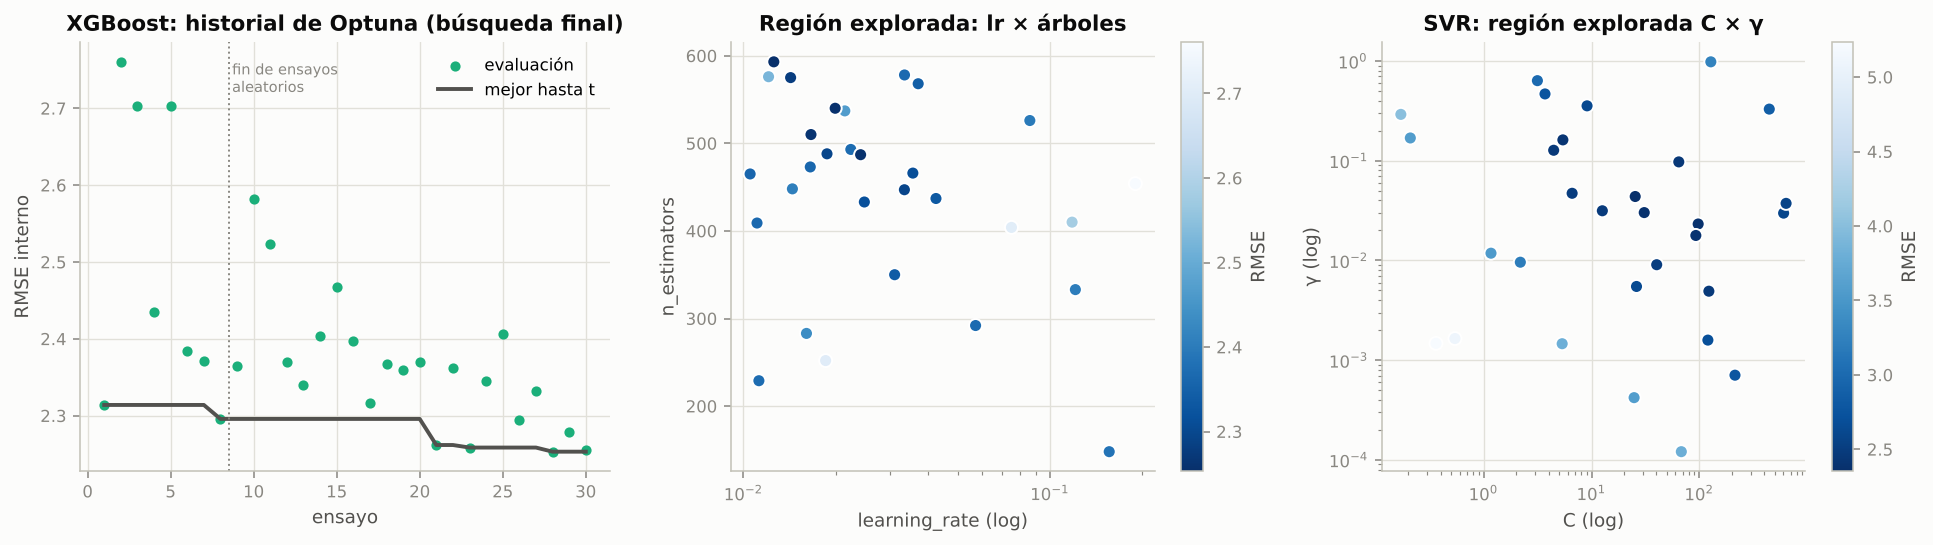

In [11]:
fin = {r["model"]: r for r in resA if r["fold"] == "final" and r["method"] == "Bayesiana"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
h = pd.DataFrame(fin["XGBoost"]["history"])
p = pd.json_normalize(h["params"])
axes[0].scatter(h["eval"], h["rmse"], s=18, color=SERIES[2], label="evaluación")
axes[0].plot(h["eval"], h["rmse"].cummin(), color=INK2, lw=2, label="mejor hasta t")
axes[0].axvline(8.5, color=MUTED, ls=":", lw=1)
axes[0].text(8.7, h["rmse"].max(), "fin de ensayos\naleatorios", fontsize=7.5, color=MUTED, va="top")
axes[0].set(xlabel="ensayo", ylabel="RMSE interno", title="XGBoost: historial de Optuna (búsqueda final)")
axes[0].legend()
sc = axes[1].scatter(p["learning_rate"], p["n_estimators"], c=h["rmse"], cmap="Blues_r", s=45, edgecolor="white")
axes[1].set(xscale="log", xlabel="learning_rate (log)", ylabel="n_estimators", title="Región explorada: lr × árboles")
fig.colorbar(sc, ax=axes[1], label="RMSE")
hs = pd.DataFrame(fin["SVR"]["history"])
ps = pd.json_normalize(hs["params"])
sc = axes[2].scatter(ps["C"], ps["gamma"], c=hs["rmse"], cmap="Blues_r", s=45, edgecolor="white")
axes[2].set(xscale="log", yscale="log", xlabel="C (log)", ylabel="γ (log)", title="SVR: región explorada C × γ")
fig.colorbar(sc, ax=axes[2], label="RMSE")
plt.tight_layout()

**Interpretación.** En XGBoost, los 8 ensayos aleatorios iniciales dan RMSE entre 2.31 y 2.76. A partir del
ensayo 9 el TPE concentra las propuestas en la región de *learning rate* bajo (0.01–0.04) con muchos
árboles (400–600), que es donde están los puntos más oscuros (mejores), y mejora el mínimo en los ensayos
8, 21, 23 y 28. Las evaluaciones posteriores siguen explorando (algunas con RMSE > 2.4), que es el equilibrio
exploración–explotación de EI. En SVR el TPE converge a una franja diagonal C × γ (C ≈ 10–600, γ ≈ 10⁻³–10⁻¹)
y evita las combinaciones de γ muy pequeño con C bajo (subajuste, RMSE > 4).

## 2.7 Algoritmo genético (DEAP): operadores y diversidad

| Componente | Elección | Justificación |
|---|---|---|
| Representación | Genoma real en [0, 1]^d, decodificado a cada hiperparámetro (log, entero o categórico) | Un mismo operador sirve para todos los tipos |
| Selección | Torneo de tamaño 3 | Presión selectiva moderada e invariante a la escala del RMSE (la ruleta depende de la magnitud del fitness) |
| Cruce | BLX-α (`cxBlend`, α = 0.5), p = 0.7 | Produce hijos dentro y alrededor del segmento entre padres: explora el continuo |
| Mutación | Gaussiana σ = 0.15 sobre el genoma, prob. por gen max(1/d, 0.34), p = 0.3 por individuo | Pasos locales que evitan el estancamiento |
| Elitismo | El mejor individuo pasa intacto | La mejor solución nunca se pierde |
| Población | 10 individuos; ~3 generaciones con 30 evaluaciones | Con el mismo presupuesto que los otros métodos |

Las configuraciones repetidas se toman de una caché y no consumen presupuesto.

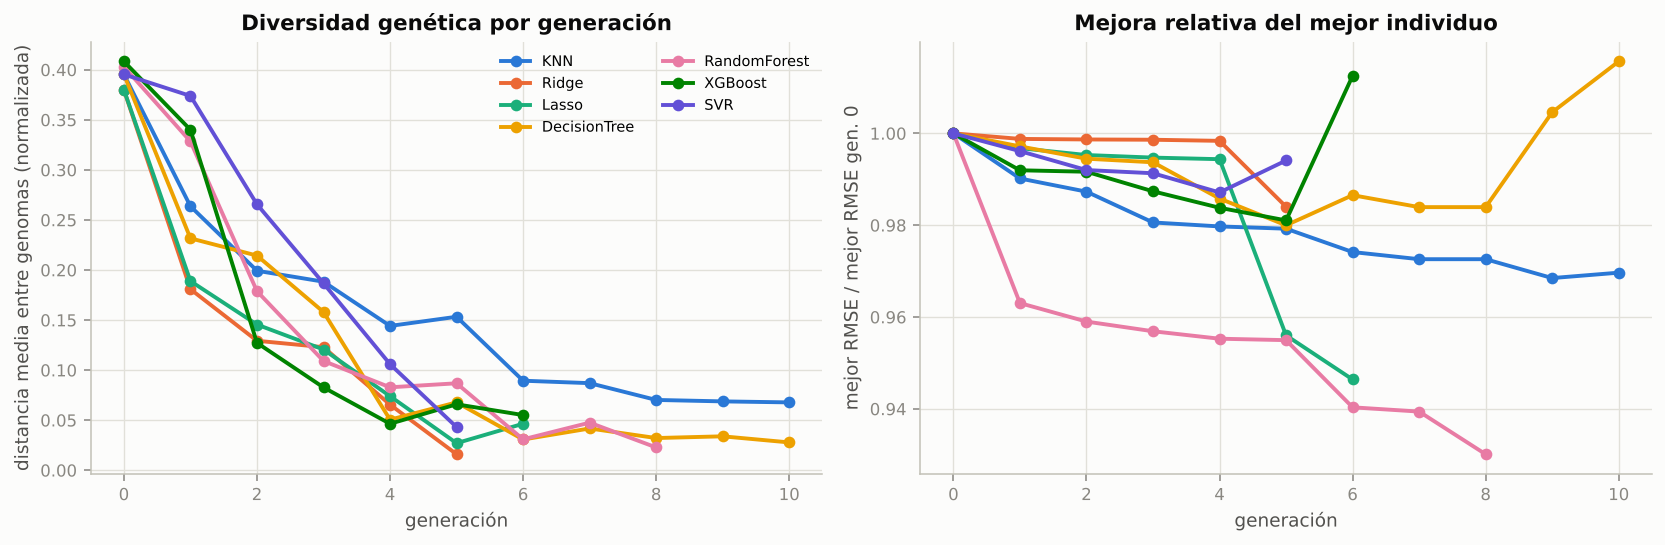

,diversidad media,evaluaciones acumuladas
gen,,
0,0.394,9.857
1,0.272,14.971
2,0.180,20.071
3,0.138,23.843
4,0.081,26.700
5,0.082,26.978
6,0.061,24.190
7,0.066,24.316
8,0.053,24.667


In [12]:
gens = []
for r in resA:
    if r["method"] == "Genetica" and r["fold"] != "final":
        for g in r["extra"]["generations"]:
            gens.append({"model": r["model"], "fold": r["fold"], **g})
gens = pd.DataFrame(gens)
# En espacios discretos (p. ej. Ridge 1-D, KNN) los hijos repetidos salen de caché y el GA sigue
# generando generaciones sin evaluar; se analizan las 10 primeras, donde ocurre la búsqueda real.
gens_all = gens.copy()
gens = gens[gens.gen <= 10]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m in MODEL_ORDER:
    s = gens[gens.model == m].groupby("gen")
    axes[0].plot(s["diversity"].mean().index, s["diversity"].mean().values, marker="o", color=MODEL_COLORS[m], label=m)
    b = s["best"].mean()
    axes[1].plot(b.index, (b / b.iloc[0]).values, marker="o", color=MODEL_COLORS[m], label=m)
axes[0].set(xlabel="generación", ylabel="distancia media entre genomas (normalizada)", title="Diversidad genética por generación")
axes[1].set(xlabel="generación", ylabel="mejor RMSE / mejor RMSE gen. 0", title="Mejora relativa del mejor individuo")
axes[0].legend(ncol=2, fontsize=7.5)
plt.tight_layout()
gens.groupby("gen")[["diversity", "n_evals"]].mean().rename(columns={"diversity": "diversidad media", "n_evals": "evaluaciones acumuladas"})

**Interpretación.**

- La diversidad genética cae de 0.39 en la población inicial a ≈ 0.14 en la generación 3 y ≈ 0.06–0.08
  desde la generación 4–5: la población converge rápido. Con 30 evaluaciones y población 10 el GA solo
  alcanza ~3 generaciones "productivas"; el torneo de tamaño 3 más el elitismo concentran la población
  alrededor de los mejores individuos, lo que es un indicio de **convergencia prematura**.
- En espacios pequeños o discretos (KNN, Ridge, árbol) los hijos repiten configuraciones ya evaluadas (se
  toman de caché) y el algoritmo genera más generaciones sin gastar presupuesto. Por eso el número de
  evaluaciones acumuladas se estanca cerca de 24–27.
- Mejoras posibles con más presupuesto: población mayor, mutación adaptativa (σ creciente cuando la
  diversidad cae) o reinicios parciales. Con este presupuesto el GA es competitivo en calidad final
  (regret final mediano 0.02 %), pero más lento que la Bayesiana.

## 2.8 Estabilidad frente a semillas aleatorias

Se repiten las búsquedas Random, Bayesiana y Genética con 5 semillas distintas en el primer pliegue
externo para XGBoost y Decision Tree (los modelos con aleatoriedad propia y bajo costo por evaluación).
Grid Search es determinística. El resultado se guarda en `results/seed_stability.csv`.

In [13]:
import time
from src.data import load_model_data, split_dev_test, xyg, outer_cv
from src.optimizers import SEARCHERS

path = C.RESULTS_DIR / "seed_stability.csv"
if path.exists():
    seeds_df = pd.read_csv(path)
else:
    df = load_model_data()
    dev, test = split_dev_test(df)
    X, y, g = xyg(dev)
    tr, te = next(outer_cv().split(X, y, g))
    rows = []
    for m in ["XGBoost", "DecisionTree"]:
        for me in ["Random", "Bayesiana", "Genetica"]:
            for sd in [0, 1, 2, 3, 4]:
                t0 = time.perf_counter()
                r = SEARCHERS[me](MODELS[m], X.iloc[tr], y[tr], g[tr], C.MAIN_SCENARIO, C.BUDGET, sd)
                pipe = MODELS[m].make_pipeline(r["best_params"], C.MAIN_SCENARIO, sd).fit(X.iloc[tr], y[tr])
                rm = float(np.sqrt(np.mean((y[te] - pipe.predict(X.iloc[te])) ** 2)))
                rows.append({"model": m, "method": me, "seed": sd, "best_inner_rmse": r["best_inner_rmse"],
                             "outer_rmse": rm, "time_s": time.perf_counter() - t0,
                             "params": json.dumps(r["best_params"], default=str)})
    seeds_df = pd.DataFrame(rows)
    seeds_df.to_csv(path, index=False)
seeds_df.groupby(["model", "method"]).agg(
    inner_media=("best_inner_rmse", "mean"), inner_sd=("best_inner_rmse", "std"),
    externo_media=("outer_rmse", "mean"), externo_sd=("outer_rmse", "std"),
    externo_min=("outer_rmse", "min"), externo_max=("outer_rmse", "max"))

inner_media  inner_sd  ...  externo_min  externo_maxmodel        method                            ...                          DecisionTree Bayesiana        2.473     0.037  ...        1.646        1.865             Genetica         2.493     0.076  ...        1.739        1.922             Random           2.512     0.058  ...        1.809        1.872XGBoost      Bayesiana        2.042     0.009  ...        1.899        1.993             Genetica         2.049     0.024  ...        1.900        1.953             Random           2.082     0.029  ...        1.917        2.038[6 rows x 6 columns]

**Interpretación.**

- **XGBoost:** la Bayesiana es la más estable frente a la semilla (desviación del RMSE interno 0.009, frente
  a 0.024 del GA y 0.029 de Random) y además alcanza el mejor RMSE interno medio (2.042). En el pliegue
  externo las tres quedan en 1.92–1.96 con desviación ≤ 0.05.
- **Decision Tree:** la variabilidad es mayor (desviación externa hasta 0.08), porque un árbol único es
  inestable: pequeñas diferencias en hiperparámetros cambian la estructura del árbol.
- En todos los casos la dispersión por semilla (≤ 0.08) es mucho menor que la dispersión entre pliegues
  externos (≈ 0.6): la incertidumbre dominante viene de **qué activos** caen en prueba, no de la semilla.

## 2.9 Escenario B: efecto de incluir `BrentDifferential`

In [14]:
mtB = mt[mt["scenario"] == "B_con_BD"].set_index("model")
a_bayes = mtA[mtA.method == "Bayesiana"].set_index("model")
cmp = pd.DataFrame({
    "RMSE externo A (sin BD)": a_bayes["outer_rmse_mean"], "RMSE externo B (con BD)": mtB["outer_rmse_mean"],
    "R² externo A": a_bayes["outer_r2_mean"], "R² externo B": mtB["outer_r2_mean"],
    "RMSE prueba A": a_bayes["test_rmse"], "RMSE prueba B": mtB["test_rmse"],
}).loc[MODEL_ORDER]
cmp["mejora RMSE (%)"] = 100 * (1 - cmp["RMSE externo B (con BD)"] / cmp["RMSE externo A (sin BD)"])
cmp

,RMSE externo A (sin BD),RMSE externo B (con BD),R² externo A,R² externo B,RMSE prueba A,RMSE prueba B,mejora RMSE (%)
model,,,,,,,
KNN,2.613,2.172,0.758,0.826,2.128,1.755,16.861
Ridge,2.685,2.194,0.749,0.829,2.589,2.143,18.306
Lasso,2.705,2.226,0.744,0.824,2.640,2.196,17.706
DecisionTree,2.491,2.212,0.768,0.819,1.987,1.439,11.190
RandomForest,2.076,1.453,0.845,0.925,1.654,1.192,29.985
XGBoost,2.058,1.428,0.848,0.923,1.624,1.258,30.635
SVR,2.187,1.470,0.835,0.923,2.160,1.328,32.768


**Interpretación.** Agregar `BrentDifferential` reduce el RMSE externo entre 11 % (árbol) y 33 % (SVR), y
los mejores modelos pasan de R² ≈ 0.85 a ≈ 0.92. La mejora es mayor en los modelos flexibles (RF, XGBoost,
SVR: 30–33 %) que en los lineales (17–18 %), lo que indica que BD interactúa con la geografía. Esta mejora
**no** es habilidad predictiva adicional en sentido estricto: BD es un sumando del target. Si en el uso real
el diferencial se conoce antes que el costo (p. ej., por contratos de venta del crudo), el escenario B es
legítimo y mucho más preciso; si no, el escenario A es la estimación honesta. El capítulo 5 confirma la
diferencia con el test de Clark-West (B anida a A).